# Flight Delay Prediction: American Airlines

In this notebook we build a model that predicts whether an **American Airlines (AA)** domestic flight will be delayed.

We use data from the **Bureau of Transportation Statistics (BTS)**, the *Reporting Carrier On-Time Performance* dataset. It has one row per US domestic flight, and we use all of 2025 (January–December).

## 1. Introduction

### Business question
> *"Can American Airlines' operations team use ML to predict flight delays (>15 min) before departure for proactive resource allocation?"*

Delays are expensive. A study funded by the FAA (Ball et al., 2010) estimated that flight delays cost the US economy **about $33 billion a year**. The costs land on airlines (crew, fuel, maintenance), on passengers (lost time) and on the wider economy.

If the operations team knows a flight is likely to be delayed, they can act before it happens. For example, they can have a spare aircraft or crew ready, move gate staff, or rebook passengers with tight connections.

### ML question
> *"Can we predict whether an American Airlines flight will arrive more than 15 minutes late, using only information available 2 hours before departure?"*

This is a **binary classification** problem:

- Each row is one scheduled AA flight.
- The target is `Delayed`. It is `1` if the flight arrives more than 15 minutes late (the official US Department of Transportation definition) and `0` otherwise.
- We make the prediction **2 hours before departure**. So we can only use what is known at that point: the schedule (date, time, route, distance), which aircraft is assigned (`Tail_Number`) and historical patterns. Anything we only learn at or after departure is off limits.

### Imports
All libraries are imported here in one place.

In [1]:
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from fairlearn.metrics import (
    MetricFrame,
    false_positive_rate,
    selection_rate,
    true_positive_rate,
)
from fairlearn.postprocessing import ThresholdOptimizer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

# Consistent colour palette for all plots
COLOR_DELAYED = "#eb6834"  # orange: delayed
COLOR_ONTIME = "#2a78d6"   # blue: on time
COLOR_REF = "#8a8984"      # grey: reference line

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#d6d5d0",
    "grid.color": "#ecebe7",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

RANDOM_STATE = 42

## 2. Data Loading & Cleaning

### 2.1 Download the raw data

BTS publishes one zip file per month. The cell below goes through all 12 months of 2025 and:

1. Downloads the zip file to `data/`, unless we already have it.
2. Reads the CSV file inside it with **all** of its columns (more than 100).
3. Keeps only the columns we need.

We do the column selection month by month. Loading all columns for 7 million flights at once would not fit in memory on a normal laptop.

These are the columns we keep:

| Column | Why we keep it |
|---|---|
| `FlightDate`, `Month`, `DayOfWeek`, `CRSDepTime` | When the flight is scheduled. Known in advance |
| `Origin`, `Dest`, `Distance` | The route. Known in advance |
| `Tail_Number` | Which aircraft flies it. Known 2 hours before departure |
| `Reporting_Airline` | So we can filter to AA |
| `Cancelled`, `Diverted` | So we can remove flights that never arrived |
| `ArrDelay` | To build the target |
| `CarrierDelay`, `WeatherDelay`, `NASDelay`, `LateAircraftDelay`, `SecurityDelay` | Reasons for the delay. Used **only for exploration**, never as features |

In [2]:
YEAR = 2025
MONTHS = range(1, 13)
URL_TEMPLATE = (
    "https://transtats.bts.gov/PREZIP/"
    "On_Time_Reporting_Carrier_On_Time_Performance_1987_present_{year}_{month}.zip"
)

DELAY_CAUSES = ["CarrierDelay", "WeatherDelay", "NASDelay", "LateAircraftDelay", "SecurityDelay"]
COLUMNS = [
    "FlightDate", "Month", "DayOfWeek", "Origin", "Dest", "CRSDepTime",
    "ArrDelay", "Cancelled", "Diverted", "Distance", "Tail_Number",
    *DELAY_CAUSES, "Reporting_Airline",
]

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

monthly_frames = []

for month in MONTHS:
    url = URL_TEMPLATE.format(year=YEAR, month=month)
    zip_path = DATA_DIR / f"ontime_{YEAR}_{month:02d}.zip"

    # 1) Download (only if we don't already have the file)
    if not zip_path.exists():
        print(f"Downloading {url} ...")
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(zip_path, "wb") as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)

    # 2) Read the CSV file directly from the zip, with all columns
    with zipfile.ZipFile(zip_path) as zf:
        csv_name = next(n for n in zf.namelist() if n.lower().endswith(".csv"))
        with zf.open(csv_name) as f:
            df_month = pd.read_csv(f, low_memory=False)

    print(f"{YEAR}-{month:02d}: {len(df_month):,} rows, {df_month.shape[1]} columns available")

    # 3) Keep only the columns we need
    monthly_frames.append(df_month[COLUMNS])

# 4) Combine all months into one DataFrame
raw = pd.concat(monthly_frames, ignore_index=True)
print(f"\nTotal: {len(raw):,} flights (all airlines), {raw.shape[1]} columns selected")

2025-01: 539,747 rows, 110 columns available
2025-02: 504,884 rows, 110 columns available
2025-03: 600,872 rows, 110 columns available
2025-04: 583,950 rows, 110 columns available
2025-05: 605,648 rows, 110 columns available
2025-06: 611,575 rows, 110 columns available
2025-07: 631,428 rows, 110 columns available
2025-08: 602,378 rows, 110 columns available
2025-09: 562,439 rows, 110 columns available
2025-10: 605,844 rows, 110 columns available
2025-11: 570,550 rows, 110 columns available
2025-12: 582,304 rows, 110 columns available

Total: 7,001,619 flights (all airlines), 17 columns selected


### 2.2 Keep only American Airlines

The dataset covers every US airline. We keep only AA's flights. After that, every row has the same airline, so we drop the `Reporting_Airline` column.

In [3]:
df = raw[raw["Reporting_Airline"] == "AA"].drop(columns=["Reporting_Airline"])

print(f"AA flights: {len(df):,} of {len(raw):,} ({len(df) / len(raw):.1%})")

AA flights: 973,653 of 7,001,619 (13.9%)


### 2.3 Remove cancelled and diverted flights

A cancelled flight never takes off, and a diverted flight lands somewhere else. Neither has a real arrival delay, so we can't say whether they were "late". We remove them.

After that, the `Cancelled` and `Diverted` columns only contain 0, so we drop them too.

In [4]:
n_before = len(df)

df = df[(df["Cancelled"] != 1) & (df["Diverted"] != 1)]
df = df.drop(columns=["Cancelled", "Diverted"])

print(f"Removed {n_before - len(df):,} cancelled/diverted flights")
print(f"Remaining: {len(df):,} rows")

Removed 20,812 cancelled/diverted flights
Remaining: 952,841 rows


### 2.4 Remove rows with no arrival delay

We build the target from `ArrDelay`. If it is missing, we can't tell whether the flight was late, so we drop the row.

In [5]:
n_before = len(df)

df = df.dropna(subset=["ArrDelay"]).reset_index(drop=True)

print(f"Removed {n_before - len(df):,} rows with missing ArrDelay")
print(f"Remaining: {len(df):,} rows")

Removed 0 rows with missing ArrDelay
Remaining: 952,841 rows


### 2.5 Create the target: `Delayed`

We use the official definition: a flight is delayed if it arrives **more than 15 minutes** after its scheduled time.

- `Delayed = 1`: delayed (`ArrDelay > 15`)
- `Delayed = 0`: on time

In [6]:
df["Delayed"] = (df["ArrDelay"] > 15).astype(int)

### 2.6 Avoid cheating: target leakage

Our model has to predict 2 hours before departure. So it may only use information we actually have at that point. If it uses information from the future, it will look great in testing and fail in practice. This is called **target leakage**. Kapoor & Narayanan (2023) show it is one of the most common mistakes in machine learning projects.

Two groups of columns would leak the answer:

- **`ArrDelay` is the answer itself.** If we know how late a flight arrived, we already know whether it was delayed.
- **The delay cause columns** (`CarrierDelay`, `WeatherDelay`, `NASDelay`, `LateAircraftDelay`, `SecurityDelay`) are only filled in after the flight lands, and only when it was delayed. Using them would be cheating.

The delay causes are still useful for *understanding* delays, for example how many are caused by a late incoming aircraft. So we move them, together with `ArrDelay`, into a separate DataFrame called `delay_causes` for the exploration later. Then we remove them from the main dataset, so they can't end up as features by accident.

In [7]:
# Separate DataFrame for EDA: same index as df, so they can be joined again
delay_causes = df[["ArrDelay", *DELAY_CAUSES]].copy()

# Remove the leakage columns from the main dataset
df = df.drop(columns=["ArrDelay", *DELAY_CAUSES])

print("delay_causes:", delay_causes.shape)
print("df:          ", df.shape)
print("Columns in df:", list(df.columns))

delay_causes: (952841, 6)
df:           (952841, 9)
Columns in df: ['FlightDate', 'Month', 'DayOfWeek', 'Origin', 'Dest', 'CRSDepTime', 'Distance', 'Tail_Number', 'Delayed']


### 2.7 Strengths and limitations of the data

What the data does well:
- It contains every AA domestic flight in 2025, not a sample.
- It is an official source with the same definitions everywhere.
- A full year covers all seasons: winter storms, summer peaks and holidays.
- About 950,000 flights is plenty for training and testing.
- `Tail_Number` lets us follow each aircraft through its day.

What it can't tell us:
- There is no weather data, even though weather causes many delays.
- It only covers one year, so we can't check whether patterns hold in 2026.
- Removing cancelled flights hides the worst days, because cancellations cluster on bad days.
- International flights are not included.
- There is no operational data, such as passenger numbers, staffing or maintenance.
- It is observational data. We can find patterns, but not prove what causes delays.

### 2.8 Class balance

How many flights are delayed compared with on time?

This matters because accuracy can be misleading when the classes are uneven. A model that always says "on time" would be right most of the time and still be useless. We will handle this later with class weights and metrics such as ROC-AUC and PR-AUC.

              Count  Share
On time (0)  714611  75.0%
Delayed (1)  238230  25.0%


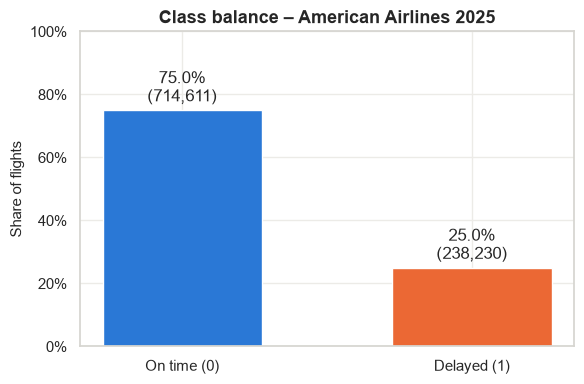

In [8]:
counts = df["Delayed"].value_counts().sort_index()
shares = counts / counts.sum()

balance = pd.DataFrame({"Count": counts, "Share": shares.map("{:.1%}".format)})
balance.index = ["On time (0)", "Delayed (1)"]
print(balance)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(balance.index, shares.values, color=[COLOR_ONTIME, COLOR_DELAYED], width=0.55)
ax.bar_label(bars, labels=[f"{s:.1%}\n({c:,})" for s, c in zip(shares, counts)], padding=3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.set_ylabel("Share of flights")
ax.set_title("Class balance – American Airlines 2025")
plt.tight_layout()
plt.show()

### 2.9 Save the cleaned datasets

We save two files, so the next sections can start from here without downloading and cleaning everything again:

- `cleaned_flights_aa.csv`: the main dataset we model on.
- `delay_causes_aa.csv`: `ArrDelay` and the delay causes, for exploration only. It has the same rows in the same order as the main dataset.

In [9]:
df.to_csv("cleaned_flights_aa.csv", index=False)
delay_causes.to_csv("delay_causes_aa.csv", index=False)

print(f"Saved cleaned_flights_aa.csv ({len(df):,} rows, {df.shape[1]} columns)")
print(f"Saved delay_causes_aa.csv ({len(delay_causes):,} rows, {delay_causes.shape[1]} columns)")
display(df.head())

Saved cleaned_flights_aa.csv (952,841 rows, 9 columns)
Saved delay_causes_aa.csv (952,841 rows, 6 columns)


,FlightDate,Month,DayOfWeek,Origin,Dest,CRSDepTime,Distance,Tail_Number,Delayed
0,2025-01-01,1,3,JFK,LAX,659,2475.0,N104NN,0
1,2025-01-02,1,4,JFK,LAX,659,2475.0,N110AN,0
2,2025-01-03,1,5,JFK,LAX,659,2475.0,N106NN,0
3,2025-01-04,1,6,JFK,LAX,700,2475.0,N117AN,0
4,2025-01-05,1,7,JFK,LAX,659,2475.0,N104NN,0


## 3. Exploratory Data Analysis

Before we build any models, we look at when and where AA's flights get delayed. This tells us which features are likely to be useful and what patterns the model should be able to pick up. Each plot below shows the **delay rate**: the share of flights that arrived more than 15 minutes late.

### 3.1 Load the data

We load the cleaned dataset and add one feature: `DepHour`, the scheduled departure hour.

`CRSDepTime` is stored as `hhmm` (e.g. `1435` = 14:35), so dividing by 100 and dropping the remainder gives the hour (14).

In [10]:
df = pd.read_csv("cleaned_flights_aa.csv")
df["DepHour"] = df["CRSDepTime"] // 100

OVERALL_RATE = df["Delayed"].mean()
print(f"Loaded {len(df):,} flights. Overall delay rate: {OVERALL_RATE:.1%}")


def add_reference(ax):
    """Draw the overall delay rate as a dashed reference line."""
    ax.axhline(OVERALL_RATE, color=COLOR_REF, linestyle="--", linewidth=1.2,
               label=f"Overall average ({OVERALL_RATE:.1%})")
    ax.legend(frameon=False, loc="upper left")

Loaded 952,841 flights. Overall delay rate: 25.0%


### 3.2 Delay rate by departure hour

Does the time of day matter? If delays build up as aircraft fly several legs a day, later flights should be delayed more often.

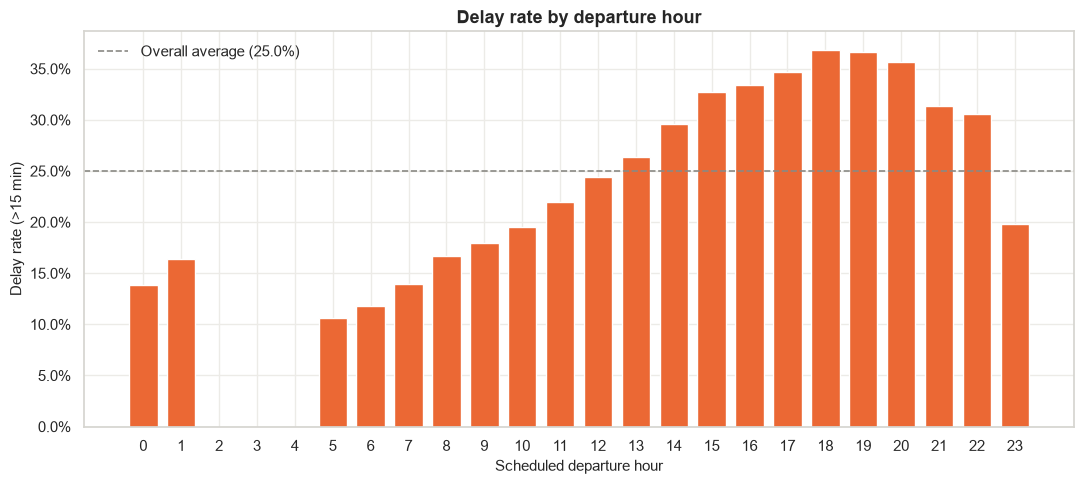

In [11]:
rate_hour = df.groupby("DepHour")["Delayed"].mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(rate_hour.index, rate_hour.values, color=COLOR_DELAYED, width=0.75)
add_reference(ax)

ax.set_xticks(range(24))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Scheduled departure hour")
ax.set_ylabel("Delay rate (>15 min)")
ax.set_title("Delay rate by departure hour")
plt.tight_layout()
plt.show()

**What we see:** The delay rate climbs steadily through the day. It goes from about 11% for 5 am departures to about 37% around 6–7 pm, before dropping late at night. There are almost no departures between 2 and 4 am, and very few around midnight.

**Why it matters:** This is the **cascade effect**. An aircraft flies several legs a day, and a delay on an early leg carries over to the next ones. `DepHour` will probably be one of the strongest features.

### 3.3 Delay rate by month

Are some times of year worse than others?

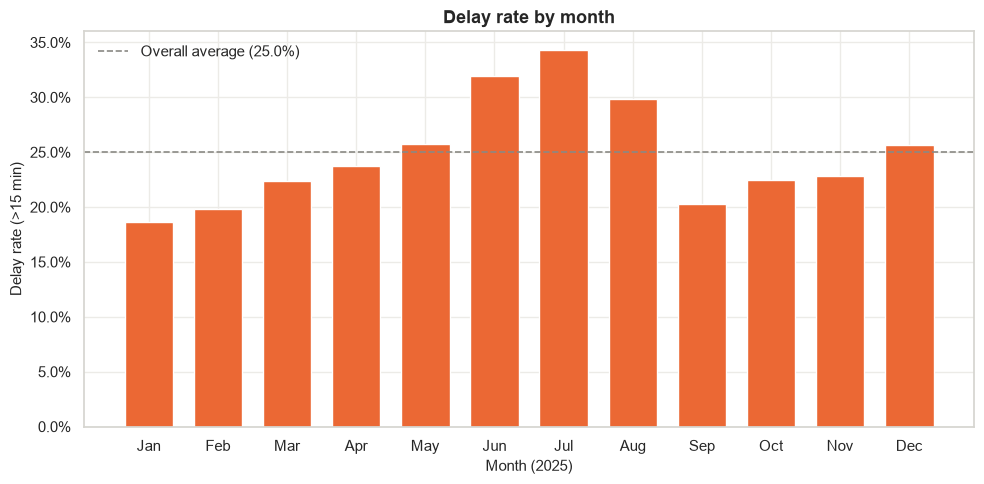

In [12]:
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

rate_month = df.groupby("Month")["Delayed"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(MONTH_NAMES, rate_month.values, color=COLOR_DELAYED, width=0.7)
add_reference(ax)

ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Month (2025)")
ax.set_ylabel("Delay rate (>15 min)")
ax.set_title("Delay rate by month")
plt.tight_layout()
plt.show()

**What we see:** There is a clear **summer peak**. June and July are the worst months (32% and 34%), when traffic is high and thunderstorms are common. **December** is also above average (26%) because of holiday traffic and winter weather. January and February are the calmest months (19–20%).

**Why it matters:** `Month` captures seasonal patterns, so it should help the model. The effect is smaller than for departure hour, though.

### 3.4 Delay rate by day of week and distance

Two more features to check:

- **Day of week:** does traffic on certain days, such as busy weekend travel, lead to more delays?
- **Distance:** are long flights delayed more often than short ones? We group flights into 500-mile bins.

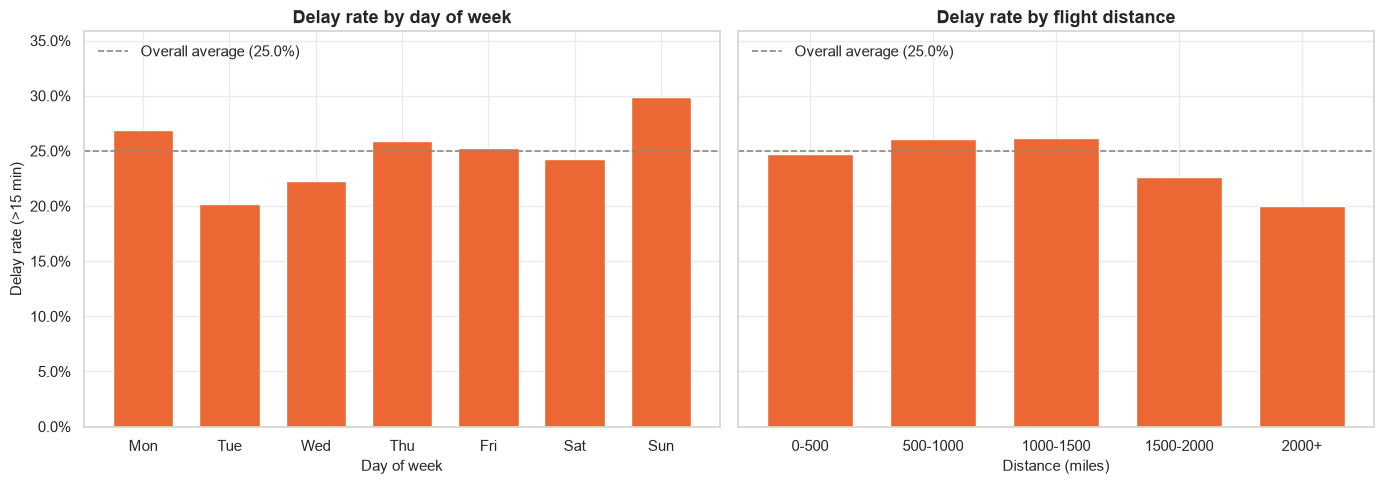

In [13]:
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
DISTANCE_BINS = [0, 500, 1000, 1500, 2000, np.inf]
DISTANCE_LABELS = ["0-500", "500-1000", "1000-1500", "1500-2000", "2000+"]

rate_weekday = df.groupby("DayOfWeek")["Delayed"].mean()
distance_bin = pd.cut(df["Distance"], bins=DISTANCE_BINS, labels=DISTANCE_LABELS, right=False)
rate_distance = df.groupby(distance_bin, observed=True)["Delayed"].mean()

fig, (ax_day, ax_dist) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax_day.bar(WEEKDAYS, rate_weekday.values, color=COLOR_DELAYED, width=0.7)
add_reference(ax_day)
ax_day.set_xlabel("Day of week")
ax_day.set_ylabel("Delay rate (>15 min)")
ax_day.set_title("Delay rate by day of week")

ax_dist.bar(DISTANCE_LABELS, rate_distance.values, color=COLOR_DELAYED, width=0.7)
add_reference(ax_dist)
ax_dist.set_xlabel("Distance (miles)")
ax_dist.set_title("Delay rate by flight distance")

ax_day.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax_day.set_ylim(0, max(rate_weekday.max(), rate_distance.max()) * 1.2)
plt.tight_layout()
plt.show()

**What we see:** **Sunday** has the highest delay rate (30%), followed by Monday (27%). These are the busiest return-travel days after the weekend. Tuesday is the calmest day (20%). Saturday (24%) is actually slightly below average, so the effect is about Sunday and Monday rather than the weekend as a whole.

Distance makes little difference for most flights: everything up to 1,500 miles sits at 25–26%. Only the longest flights are delayed less often (23% for 1,500–2,000 miles and 20% for 2,000+). A likely reason is that long flights have more room in the schedule to make up lost time in the air.

**Why it matters:** `DayOfWeek` has a clear effect of about 10 percentage points between the best and worst day, so it is worth keeping. `Distance` is a weak feature on its own, but may still help in combination with route and airport.

### 3.5 Delay rate at AA's 10 busiest airports

AA runs a hub-and-spoke network: many flights go through a few large hubs. Are the hubs more delay-prone than other busy airports?

The five hubs (DFW, CLT, MIA, ORD, PHX) are shown in solid colour with bold labels. The other busy airports are shown in a lighter shade.

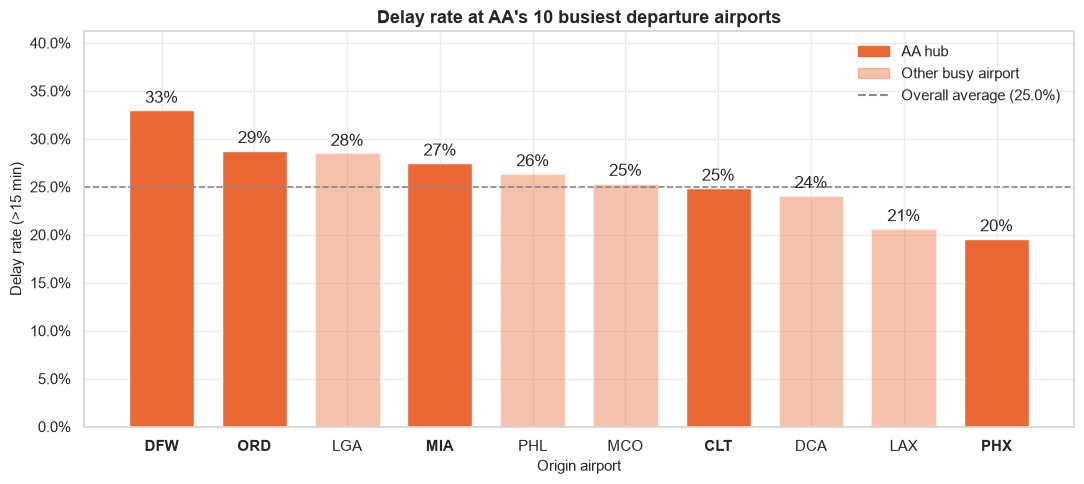

In [14]:
HUBS = ["DFW", "CLT", "MIA", "ORD", "PHX"]

top10 = df["Origin"].value_counts().head(10).index
rate_airport = (
    df[df["Origin"].isin(top10)]
    .groupby("Origin")["Delayed"].mean()
    .sort_values(ascending=False)
)
is_hub = rate_airport.index.isin(HUBS)

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(rate_airport.index, rate_airport.values, color=COLOR_DELAYED, width=0.7)
for bar, hub in zip(bars, is_hub):
    bar.set_alpha(1.0 if hub else 0.4)
ax.bar_label(bars, labels=[f"{r:.0%}" for r in rate_airport.values], padding=3)

for label, hub in zip(ax.get_xticklabels(), is_hub):
    label.set_fontweight("bold" if hub else "normal")

ax.axhline(OVERALL_RATE, color=COLOR_REF, linestyle="--", linewidth=1.2)
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=COLOR_DELAYED, alpha=1.0, label="AA hub"),
        plt.Rectangle((0, 0), 1, 1, color=COLOR_DELAYED, alpha=0.4, label="Other busy airport"),
        plt.Line2D([], [], color=COLOR_REF, linestyle="--", label=f"Overall average ({OVERALL_RATE:.1%})"),
    ],
    frameon=False, loc="upper right",
)

ax.set_ylim(0, rate_airport.max() * 1.25)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Origin airport")
ax.set_ylabel("Delay rate (>15 min)")
ax.set_title("Delay rate at AA's 10 busiest departure airports")
plt.tight_layout()
plt.show()

**What we see:** Being a hub does not automatically mean more delays. **DFW**, AA's biggest hub, has the highest delay rate (33%), and ORD and MIA are also above average. But **CLT** (25%) is right at the average, and **PHX** (20%) has the lowest rate of the ten. Congested non-hub airports like LGA and PHL are also well above average.

**Why it matters:** Delay rates differ a lot between airports (20% to 33% among just these ten). So `Origin`, and probably `Dest`, carry useful information. A simple hub/non-hub flag would miss most of it, because the hubs themselves differ so much.

### 3.6 What causes the delays?

For every delayed flight, the airline reports how many minutes were caused by each of five reasons:

- **LateAircraftDelay:** the incoming aircraft arrived late (the cascade effect)
- **CarrierDelay:** the airline's own fault, e.g. crew, maintenance, baggage or fuelling
- **NASDelay:** the air traffic system, e.g. congestion or air traffic control
- **WeatherDelay:** extreme weather
- **SecurityDelay:** security problems, e.g. evacuations or long screening queues

For each delayed flight, we compute each cause's share of the total delay, then average those shares across all delayed flights.

**Note:** As explained in section 2.6, these columns are **not** used as features. They are only filled in after the flight lands, so using them would leak the answer. We use them here only to understand what drives delays.

Delayed flights: 238,230
Late aircraft (cascade)     41.2%
Carrier                     29.4%
Air traffic system (NAS)    25.2%
Weather                      4.0%
Security                     0.2%


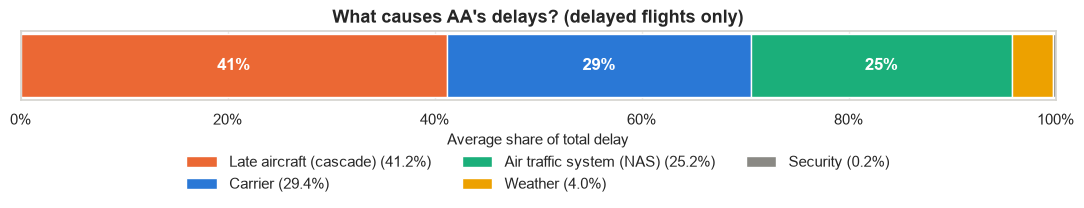

In [15]:
delay_causes = pd.read_csv("delay_causes_aa.csv")

CAUSE_LABELS = {
    "LateAircraftDelay": "Late aircraft (cascade)",
    "CarrierDelay": "Carrier",
    "NASDelay": "Air traffic system (NAS)",
    "WeatherDelay": "Weather",
    "SecurityDelay": "Security",
}
CAUSE_COLORS = [COLOR_DELAYED, COLOR_ONTIME, "#1baf7a", "#eda100", COLOR_REF]
causes = list(CAUSE_LABELS)

# Only delayed flights, where the causes are filled in
delayed = delay_causes[delay_causes["ArrDelay"] > 15]
total_minutes = delayed[causes].sum(axis=1)

# Each cause's share of the flight's total delay, averaged over all delayed flights
cause_share = (
    delayed[causes]
    .div(total_minutes, axis=0)[total_minutes > 0]
    .mean()
)
print(f"Delayed flights: {len(delayed):,}")
print(cause_share.rename(CAUSE_LABELS).map("{:.1%}".format).to_string())

fig, ax = plt.subplots(figsize=(11, 3.4))
left = 0
for cause, color in zip(causes, CAUSE_COLORS):
    share = cause_share[cause]
    ax.barh(0, share, left=left, color=color, label=f"{CAUSE_LABELS[cause]} ({share:.1%})")
    if share > 0.05:
        ax.text(left + share / 2, 0, f"{share:.0%}", ha="center", va="center",
                color="white", fontweight="bold", fontsize=12)
    left += share

ax.set_xlim(0, 1)
ax.set_yticks([])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Average share of total delay")
ax.set_title("What causes AA's delays? (delayed flights only)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.6), ncol=3)
plt.tight_layout()
plt.show()

**What we see:** **Late aircraft** is the biggest cause, at about 41% of the average delay. The airline's own issues (carrier, about 29%) and the air traffic system (NAS, about 25%) come next. Extreme weather (about 4%) and security (under 1%) play a small part. Bad weather often shows up as NAS delays instead, because it slows down air traffic control.

**Why it matters:** The cascade effect is the single largest driver of delays. It also explains the departure-hour pattern in 3.2: the later in the day, the more earlier legs there are for a delay to build up on. Features that track an aircraft's previous legs (via `Tail_Number`) could therefore be valuable, as long as they only use information known 2 hours before departure.

### 3.7 Correlation matrix

Finally, we check the linear correlation between the numerical features and the target. A value near 0 means no linear relationship. Values near ±1 mean a strong one.

Two things to look for:
- **Feature vs. `Delayed`:** which features move together with delays?
- **Feature vs. feature:** are any features so strongly related that they carry the same information?

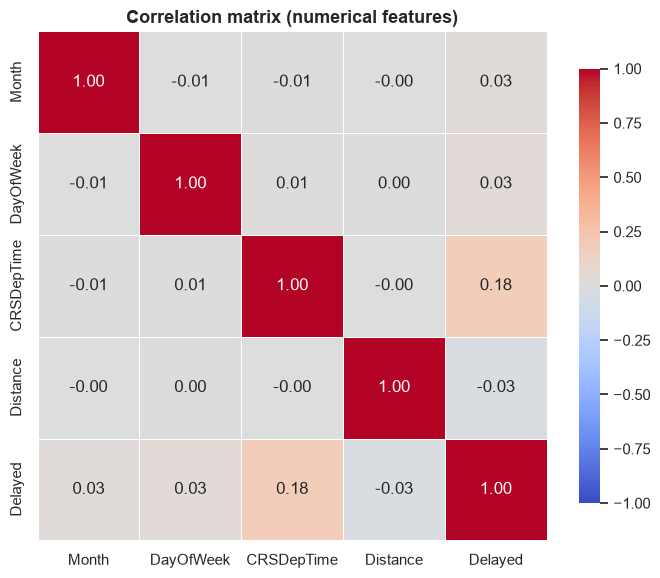

In [16]:
corr = df[["Month", "DayOfWeek", "CRSDepTime", "Distance", "Delayed"]].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation matrix (numerical features)")
plt.tight_layout()
plt.show()

**What we see:** All correlations are weak. `CRSDepTime` has the strongest link to `Delayed` (0.18), which fits the departure-hour pattern. `Month`, `DayOfWeek` and `Distance` are close to 0. The features are also unrelated to each other, so there is no redundancy.

**Why it matters:** Correlation only measures *straight-line* relationships. The month effect goes up in summer and back down in autumn, so it has a near-zero correlation even though 3.3 showed a clear pattern. This is a reason to use models that can capture non-linear patterns, such as decision trees, random forests and XGBoost.

### 3.8 EDA summary

| Feature | Strength | Why |
|---|---|---|
| `DepHour` / `CRSDepTime` | Strong | Delay rate rises from 11% to 37% through the day (cascade effect) |
| `Origin` / `Dest` | Strong | Delay rates range from 20% to 33% among the 10 busiest airports alone |
| `Month` | Moderate | Clear summer peak (34% in July vs. 19% in January), but non-linear |
| `DayOfWeek` | Moderate | Ranges from 20% (Tuesday) to 30% (Sunday) |
| `Distance` | Weak | Flat at 25–26% up to 1,500 miles; only the longest flights are less delayed (20%) |
| Delay causes | Not a feature | Leakage, but show that late incoming aircraft are the biggest driver |

## 4. Feature Engineering & Train/Test Split

Now we turn the cleaned data into the features the models will use. The rule from the ML question still applies: every feature must be **known 2 hours before departure**. That means we can only use the schedule, the route and historical patterns, never anything about how the flight actually went.

### 4.1 Basic features

In [17]:
HUBS = ["DFW", "CLT", "MIA", "ORD", "PHX"]

df = pd.read_csv("cleaned_flights_aa.csv")

# Scheduled departure hour: 1435 -> 14
df["DepHour"] = df["CRSDepTime"] // 100
df = df.drop(columns=["CRSDepTime"])

# Saturday (6) or Sunday (7)
df["IsWeekend"] = df["DayOfWeek"].isin([6, 7]).astype(int)

# Departure from one of AA's five hubs
df["IsHub"] = df["Origin"].isin(HUBS).astype(int)

# FlightDate is dropped: Month and DayOfWeek already hold the useful parts
df = df.drop(columns=["FlightDate"])
df = df[["Month", "DayOfWeek", "DepHour", "IsWeekend", "IsHub", "Distance",
         "Origin", "Dest", "Tail_Number", "Delayed"]]

print("Shape:", df.shape)
print("Columns:", list(df.columns))

Shape: (952841, 10)
Columns: ['Month', 'DayOfWeek', 'DepHour', 'IsWeekend', 'IsHub', 'Distance', 'Origin', 'Dest', 'Tail_Number', 'Delayed']


All of these come straight from the published schedule, so they are known long before the flight:

- **`Month`, `DayOfWeek`:** when the flight is scheduled. Captures the seasonal and weekly patterns from the EDA.
- **`DepHour`:** scheduled departure hour. The strongest pattern in the EDA (the cascade effect).
- **`IsWeekend`:** 1 for Saturday and Sunday. Makes it easy for a model to pick up a weekend effect.
- **`IsHub`:** 1 if the flight departs from DFW, CLT, MIA, ORD or PHX. Hub operations are busier and more complex.
- **`Distance`:** route length in miles. Fixed for each route.
- **`Origin`, `Dest`:** the airports. Still text, so they are encoded in 4.3.
- **`Tail_Number`:** the assigned aircraft, which is known at T-2 hours. We keep it for now and decide in 4.3.

### 4.2 Train/test split

We hold back 20% of the flights as a **test set**. The models never see it during training, so it tells us how well they work on new flights.

The split is **stratified**, which means both sets get the same share of delayed flights.

In [18]:
X = df.drop(columns=["Delayed"])
y = df["Delayed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {len(X_train):,} flights, delay rate {y_train.mean():.2%}")
print(f"Test:  {len(X_test):,} flights, delay rate {y_test.mean():.2%}")

Train: 762,272 flights, delay rate 25.00%
Test:  190,569 flights, delay rate 25.00%


Both sets have the same delay rate, so stratification worked.

**Why split now?** The next step calculates delay rates per airport. If we did that *before* splitting, the test flights' outcomes would be baked into the features, and the model would effectively have seen the answers for the test set. So we split first, and from here on everything is learned from the training set only.

### 4.3 Target encoding of airports

`Origin` and `Dest` are airport codes. A model can't use text directly, and with about 130 airports, one-hot encoding would add around 260 mostly-empty columns.

Instead we use **target encoding**: each airport is replaced by its **historical delay rate**. For example, a DFW departure gets DFW's delay rate.

Three details matter:

- **Smoothing.** An airport with only a handful of flights can have a delay rate of 0% or 100% by pure chance. Smoothing pulls small airports toward the overall average, while large airports keep their own rate. With `m = 20`, each airport is treated as if it had 20 extra flights at the overall average rate:

  $$\text{rate} = \frac{\text{delayed flights} + m \cdot \text{overall rate}}{\text{flights} + m}$$

- **Training data only.** The rates are calculated on the training set and then applied to both sets. Calculating them on the full data would leak test outcomes into the features. Kapoor & Narayanan (2023) list this kind of preprocessing on the full dataset as a common source of leakage.
- **Unknown airports.** If a test flight uses an airport that never appears in training, it gets the overall training delay rate.

After encoding, we drop `Origin` and `Dest`. We also drop `Tail_Number` for now to keep the model simple. Aircraft-based features, such as each aircraft's own delay history, could be added later.

In [19]:
SMOOTHING = 20  # m: pseudo-flights at the overall rate


def target_encode(train_col, test_col, y, m=SMOOTHING):
    """Smoothed delay rate per category, learned on training data only."""
    global_rate = y.mean()
    stats = y.groupby(train_col).agg(["sum", "count"])
    rates = (stats["sum"] + m * global_rate) / (stats["count"] + m)

    # Unknown categories in the test set get the overall training rate
    return train_col.map(rates), test_col.map(rates).fillna(global_rate)


for col in ["Origin", "Dest"]:
    X_train[f"{col}_delay_rate"], X_test[f"{col}_delay_rate"] = target_encode(
        X_train[col], X_test[col], y_train
    )
    n_unknown = (~X_test[col].isin(X_train[col])).sum()
    print(f"{col}: {X_train[col].nunique()} categories in train, {n_unknown} test flights with unknown {col}")

X_train = X_train.drop(columns=["Origin", "Dest", "Tail_Number"])
X_test = X_test.drop(columns=["Origin", "Dest", "Tail_Number"])

Origin: 133 categories in train, 0 test flights with unknown Origin
Dest: 133 categories in train, 0 test flights with unknown Dest


### 4.4 Final feature set

In [20]:
FEATURES = [
    "Month", "DayOfWeek", "DepHour", "IsWeekend", "IsHub", "Distance",
    "Origin_delay_rate", "Dest_delay_rate",
]
X_train = X_train[FEATURES]
X_test = X_test[FEATURES]

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
display(X_train.head())

print("Correlation with Delayed (training set):")
print(X_train.corrwith(y_train).sort_values(ascending=False).round(3).to_string())

X_train: (762272, 8)
X_test:  (190569, 8)


,Month,DayOfWeek,DepHour,IsWeekend,IsHub,Distance,Origin_delay_rate,Dest_delay_rate
74340,2,1,6,0,0,1744.0,0.206255,0.256346
129338,2,5,7,0,0,1744.0,0.206255,0.256346
569983,8,6,10,1,1,651.0,0.194840,0.272972
94657,2,4,18,0,0,950.0,0.256817,0.313663
727097,10,4,5,0,0,985.0,0.256817,0.250963


Correlation with Delayed (training set):
DepHour              0.182
Origin_delay_rate    0.109
Dest_delay_rate      0.099
IsHub                0.063
DayOfWeek            0.033
IsWeekend            0.031
Month                0.026
Distance            -0.026


We end up with **8 features**, all numerical, for 762,272 training flights and 190,569 test flights. Because the airports are now delay rates rather than text, no one-hot encoding is needed.

The correlations confirm the EDA:

- `DepHour` is the strongest single feature (0.18).
- The two airport delay rates come next (about 0.10 each), so target encoding has turned `Origin` and `Dest` into useful signals.
- The calendar features and `Distance` are weak on their own (|r| ≈ 0.03).

Remember that correlation only captures straight-line relationships. Features like `Month` may still matter in combination with others, which tree-based models can pick up.

## 5. Modelling

We now train and compare models from three model families covered in the course: **parametric** (Logistic Regression), **tree-based** (Decision Tree) and **ensembles** (Random Forest, XGBoost). For each model we show it **before and after** hyperparameter tuning, so we can see what tuning adds. We start with a naive baseline that every real model has to beat.

### 5.1 Baseline: DummyClassifier

About 75% of flights are on time, so a "model" that always predicts **on time** is already right 75% of the time. Any useful model must beat this baseline, especially on the delayed flights, which the baseline never catches.

Every model is evaluated the same way on the test set, using a shared helper function. It prints a classification report and saves the results in a `results` dictionary, which we use to compare all models at the end.

We focus on two numbers:
- **F1 for the delayed class:** balances catching delays (recall) with not raising too many false alarms (precision).
- **ROC-AUC:** how well the model ranks flights by risk, regardless of the decision threshold. 0.5 is random guessing, 1.0 is perfect.

In [21]:
results = {}


def evaluate(name, model, label, fit_time):
    """Evaluate a fitted model on the test set, print metrics and store them in `results`."""
    y_pred = model.predict(X_test)

    # Risk scores for ROC-AUC: probabilities if available, otherwise decision scores
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_proba = model.decision_function(X_test)
    else:
        y_proba = None

    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan

    results[name] = {
        "model": model,
        "y_pred": y_pred,
        "y_proba": y_proba,
        "f1": f1,
        "auc": auc,
        "label": label,
        "fit_time": fit_time,
    }

    print(classification_report(y_test, y_pred, target_names=["On Time", "Delayed"],
                                digits=3, zero_division=0))
    print(f"F1 (delayed): {f1:.3f}")
    print(f"ROC-AUC:      {auc:.3f}")
    print(f"Training time: {fit_time:.1f} s")

In [22]:
dummy = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)

start = time.time()
dummy.fit(X_train, y_train)
evaluate("Dummy", dummy, label="Dummy", fit_time=time.time() - start)

              precision    recall  f1-score   support

     On Time      0.750     1.000     0.857    142923
     Delayed      0.000     0.000     0.000     47646

    accuracy                          0.750    190569
   macro avg      0.375     0.500     0.429    190569
weighted avg      0.562     0.750     0.643    190569

F1 (delayed): 0.000
ROC-AUC:      0.500
Training time: 0.0 s


**What we see:** The baseline gets **75% accuracy** without learning anything, simply by predicting "on time" for every flight. But it catches **none** of the delayed flights (recall 0, F1 0), and its ROC-AUC is 0.5, the same as random guessing.

This is why we don't judge models on accuracy. From here on, we look at **F1 for the delayed class** and **ROC-AUC**.

### 5.2 Logistic Regression

Logistic regression is a **parametric model** (Module 4): it learns one weight per feature and assumes a **linear decision boundary** between delayed and on-time flights. It is sensitive to feature scales (e.g. `Distance` in thousands vs. `IsHub` as 0/1), so we wrap it in a `Pipeline` with a `StandardScaler`.

We use `class_weight="balanced"` so that mistakes on the rarer delayed flights count more. Without it, the model would lean toward always predicting "on time", like the baseline.

#### Before tuning: default settings

In [23]:
logreg_default = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(class_weight="balanced", solver="saga", max_iter=1000,
                                  random_state=RANDOM_STATE)),
])

start = time.time()
logreg_default.fit(X_train, y_train)
evaluate("LogReg (default)", logreg_default, label="LogReg default", fit_time=time.time() - start)

              precision    recall  f1-score   support

     On Time      0.825     0.607     0.699    142923
     Delayed      0.342     0.613     0.439     47646

    accuracy                          0.609    190569
   macro avg      0.584     0.610     0.569    190569
weighted avg      0.704     0.609     0.634    190569

F1 (delayed): 0.439
ROC-AUC:      0.645
Training time: 2.9 s


#### After tuning: GridSearchCV

We tune two hyperparameters with 5-fold cross-validation on the training set, scored by ROC-AUC:

- **`C`:** how strongly the weights are regularised. Smaller `C` means stronger regularisation and a simpler model.
- **L1 vs. L2 penalty:** L2 shrinks all weights a little. L1 can shrink weak features all the way to zero. In scikit-learn 1.8+ this is set with `l1_ratio` (0 = L2, 1 = L1), which replaces the deprecated `penalty` parameter.

That gives 4 × 2 = 8 combinations × 5 folds = 40 fits.

In [24]:
logreg_search = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(class_weight="balanced", solver="saga", max_iter=1000,
                                      random_state=RANDOM_STATE)),
    ]),
    param_grid={
        "logreg__C": [0.01, 0.1, 1, 10],
        "logreg__l1_ratio": [0, 1],  # 0 = L2 penalty, 1 = L1 penalty
    },
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)

start = time.time()
logreg_search.fit(X_train, y_train)
logreg_time = time.time() - start

print("Best params:", logreg_search.best_params_)
print(f"Best CV ROC-AUC: {logreg_search.best_score_:.4f}\n")

cv_table = (
    pd.DataFrame(logreg_search.cv_results_)
    [["param_logreg__C", "param_logreg__l1_ratio", "mean_test_score", "std_test_score"]]
    .rename(columns={"param_logreg__C": "C", "param_logreg__l1_ratio": "l1_ratio",
                     "mean_test_score": "CV ROC-AUC", "std_test_score": "Std"})
    .sort_values("CV ROC-AUC", ascending=False)
    .round(4)
)
display(cv_table)

evaluate("LogReg (tuned)", logreg_search.best_estimator_, label="LogReg tuned", fit_time=logreg_time)

Best params: {'logreg__C': 0.1, 'logreg__l1_ratio': 0}
Best CV ROC-AUC: 0.6429



,C,l1_ratio,CV ROC-AUC,Std
2,0.10,0,0.6429,0.0012
4,1.00,0,0.6429,0.0012
6,10.00,0,0.6429,0.0012
7,10.00,1,0.6429,0.0012
0,0.01,0,0.6429,0.0012
5,1.00,1,0.6429,0.0012
3,0.10,1,0.6429,0.0012
1,0.01,1,0.6429,0.0012


              precision    recall  f1-score   support

     On Time      0.825     0.607     0.699    142923
     Delayed      0.342     0.613     0.439     47646

    accuracy                          0.609    190569
   macro avg      0.584     0.610     0.569    190569
weighted avg      0.704     0.609     0.634    190569

F1 (delayed): 0.439
ROC-AUC:      0.645
Training time: 37.0 s


**What we see:**

- **Logistic regression clearly beats the baseline.** It catches about 61% of delayed flights (recall), and when it predicts a delay it is right about 34% of the time (precision). That gives an F1 of 0.44 and a ROC-AUC of 0.645.
- **Accuracy drops to 61%,** below the baseline's 75%. That is expected and fine: `class_weight="balanced"` makes the model flag many more flights as delayed, trading some false alarms for actually catching delays.
- **Tuning changes nothing.** All 8 combinations score the same CV ROC-AUC (0.643). With 760,000 training flights and only 8 features, there is far more data than parameters, so regularisation has nothing to fix. The tuned model is therefore identical to the default one, just slower to find (37 s vs. 2.5 s).

The ceiling here is the model, not its settings. Logistic regression can only draw a straight-line boundary, but the EDA showed non-linear patterns, such as the summer peak in `Month` and the evening peak in `DepHour`. Tree-based models can capture those, which is what we try next.

### 5.3 Decision Tree

A decision tree is a **tree-based model** (Module 3). It splits the data into groups by asking yes/no questions about the features, like *"Is DepHour > 15?"*. Each split picks the question that best separates delayed from on-time flights.

Unlike logistic regression, a tree can capture **non-linear patterns**, such as the summer peak and the evening peak from the EDA, and it needs no feature scaling.

We use `class_weight="balanced"` so the tree pays more attention to the smaller delayed class.

#### Before tuning: default settings

With default settings the tree has no depth limit. It keeps splitting until every leaf is pure or holds a single flight.

In [25]:
dtree_default = DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)

start = time.time()
dtree_default.fit(X_train, y_train)
evaluate("DTree (default)", dtree_default, label="DTree default", fit_time=time.time() - start)

print(f"Tree depth: {dtree_default.get_depth()}, leaves: {dtree_default.get_n_leaves():,}")

              precision    recall  f1-score   support

     On Time      0.797     0.614     0.693    142923
     Delayed      0.314     0.531     0.395     47646

    accuracy                          0.593    190569
   macro avg      0.556     0.572     0.544    190569
weighted avg      0.676     0.593     0.619    190569

F1 (delayed): 0.395
ROC-AUC:      0.587
Training time: 2.1 s
Tree depth: 47, leaves: 201,038


#### After tuning: GridSearchCV

We tune two hyperparameters that control how big and complex the tree can grow, with 5-fold cross-validation scored by ROC-AUC:

- **`max_depth`:** how many levels deep the tree can go. A deeper tree fits more detail but risks memorising the training data.
- **`min_samples_leaf`:** every leaf (end node) must have at least this many flights. Larger values force broader, more general rules.

That is 4 × 3 = 12 combinations × 5 folds = 60 fits.

We show the grid results the same way for every model from here on, so we put that in a small helper function.

In [26]:
def show_cv_results(search):
    """Print best params and show all grid combinations sorted by CV ROC-AUC."""
    print("Best params:", search.best_params_)
    print(f"Best CV ROC-AUC: {search.best_score_:.4f}\n")

    params = list(search.param_grid)
    table = (
        pd.DataFrame(search.cv_results_)
        [[f"param_{p}" for p in params] + ["mean_test_score", "std_test_score"]]
        .rename(columns={f"param_{p}": p for p in params})
        .rename(columns={"mean_test_score": "CV ROC-AUC", "std_test_score": "Std"})
        .sort_values("CV ROC-AUC", ascending=False)
        .round(4)
    )
    display(table)


dtree_search = GridSearchCV(
    estimator=DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    param_grid={
        "max_depth": [3, 5, 10, 15],
        "min_samples_leaf": [50, 100, 500],
    },
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)

start = time.time()
dtree_search.fit(X_train, y_train)
dtree_time = time.time() - start

show_cv_results(dtree_search)
evaluate("DTree (tuned)", dtree_search.best_estimator_, label="DTree tuned", fit_time=dtree_time)

Best params: {'max_depth': 15, 'min_samples_leaf': 500}
Best CV ROC-AUC: 0.6825



,max_depth,min_samples_leaf,CV ROC-AUC,Std
11,15,500,0.6825,0.0007
10,15,100,0.6808,0.0009
7,10,100,0.6804,0.0011
6,10,50,0.6801,0.0013
8,10,500,0.6801,0.0009
9,15,50,0.6765,0.0008
5,5,500,0.6615,0.0010
3,5,50,0.6614,0.0010
4,5,100,0.6614,0.0010
0,3,50,0.6424,0.0019


              precision    recall  f1-score   support

     On Time      0.836     0.654     0.734    142923
     Delayed      0.372     0.616     0.464     47646

    accuracy                          0.644    190569
   macro avg      0.604     0.635     0.599    190569
weighted avg      0.720     0.644     0.666    190569

F1 (delayed): 0.464
ROC-AUC:      0.685
Training time: 22.1 s


#### Visualising the tuned tree

The tuned tree is 15 levels deep, which is far too large to read in one picture. We therefore plot only its **top 3 levels**. These are the splits the tree found most useful, so they show which features matter most.

How to read it:

- **Each box is a node.** The first line is the yes/no question, for example `DepHour <= 14.5`. Flights that answer **yes** go to the **left** branch, **no** goes to the **right**.
- **`gini`** measures how mixed the node is: 0 means all flights in it belong to one class, and 0.5 means an even 50/50 mix.
- **`samples`** is the number of training flights in the node, and **`value`** is the class-weighted split between on-time and delayed flights. **`class`** is the majority prediction.
- **Colours** show the prediction: **orange** boxes lean towards "On Time" and **blue** boxes towards "Delayed". The stronger the colour, the purer the node. Boxes marked `(...)` continue deeper than we show. (These are scikit-learn's default colours, so they are the reverse of the orange = delayed palette used in the rest of the notebook.)

In [ ]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    dtree_search.best_estimator_,
    max_depth=3,
    feature_names=FEATURES,
    class_names=["On Time", "Delayed"],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
ax.set_title("Tuned decision tree (top 3 levels)")
plt.tight_layout()
plt.show()

**What we see:**

- **The default tree overfits badly.** With no limits it grows **47 levels deep with 201,038 leaves**, about one leaf for every four training flights. It memorises the training data and does worse than logistic regression on the test set (F1 0.395, ROC-AUC 0.587).
- **Tuning fixes this.** The best settings are **`max_depth=15`** and **`min_samples_leaf=500`**, giving **F1 0.464** and **ROC-AUC 0.685**, a big jump from the default tree. CV ROC-AUC (0.683) and test ROC-AUC (0.685) are almost the same, so the tuned tree generalises well.
- **Depth matters more than leaf size.** CV ROC-AUC rises from 0.642 at depth 3 to 0.683 at depth 15, while changing `min_samples_leaf` barely moves it. A depth-3 tree scores about the same as logistic regression (0.643): it is too simple to see more than a straight line can. Both best values sit at the edge of the grid, so a slightly deeper tree with even larger leaves might do a little better.
- **Capturing non-linear patterns helps.** The tuned tree beats logistic regression on both F1 (0.464 vs. 0.439) and ROC-AUC (0.685 vs. 0.645). It can split `DepHour` and `Month` into ranges, such as "evening" or "summer", instead of forcing one straight-line effect on them, which is exactly what the EDA suggested.

A single tree is still unstable: a small change in the training data can give a very different tree. Combining many trees should help, which is what Random Forest does next.

### 5.4 Random Forest

Random Forest is an **ensemble method using bagging** (Module 3). Instead of one tree, it trains many trees in parallel, each on a random sample of the flights and a random subset of the features. The final prediction is a majority vote.

This reduces overfitting compared with a single tree, because the individual trees' mistakes tend to cancel out.

We use `class_weight="balanced"` and `n_jobs=-1` to train the trees in parallel.

#### Before tuning: default settings

The default forest has 100 trees with no depth limit. This is the most memory-hungry model in the notebook (about 3 GB).

In [27]:
rf_default = RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)

start = time.time()
rf_default.fit(X_train, y_train)
evaluate("RF (default)", rf_default, label="RF default", fit_time=time.time() - start)

              precision    recall  f1-score   support

     On Time      0.800     0.604     0.688    142923
     Delayed      0.316     0.548     0.401     47646

    accuracy                          0.590    190569
   macro avg      0.558     0.576     0.544    190569
weighted avg      0.679     0.590     0.616    190569

F1 (delayed): 0.401
ROC-AUC:      0.618
Training time: 15.7 s


#### After tuning: GridSearchCV

We tune three hyperparameters:

- **`n_estimators`:** how many trees to grow. More trees usually help but take longer.
- **`max_depth`:** depth limit per tree, as for the single decision tree.
- **`min_samples_leaf`:** minimum flights per leaf.

That is 2 × 3 × 2 = 12 combinations × 5 folds = 60 fits. This is the slowest grid in the notebook (typically 15–30 minutes).

In [28]:
rf_search = GridSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [10, 15, 20],
        "min_samples_leaf": [50, 100],
    },
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)

start = time.time()
rf_search.fit(X_train, y_train)
rf_time = time.time() - start

show_cv_results(rf_search)
evaluate("RF (tuned)", rf_search.best_estimator_, label="RF tuned", fit_time=rf_time)

Best params: {'max_depth': 20, 'min_samples_leaf': 50, 'n_estimators': 200}
Best CV ROC-AUC: 0.6958



,n_estimators,max_depth,min_samples_leaf,CV ROC-AUC,Std
9,200,20,50,0.6958,0.0010
8,100,20,50,0.6956,0.0010
5,200,15,50,0.6944,0.0011
4,100,15,50,0.6942,0.0010
11,200,20,100,0.6929,0.0011
10,100,20,100,0.6928,0.0010
7,200,15,100,0.6921,0.0011
6,100,15,100,0.6919,0.0010
1,200,10,50,0.6845,0.0011
0,100,10,50,0.6843,0.0012


              precision    recall  f1-score   support

     On Time      0.842     0.659     0.740    142923
     Delayed      0.381     0.630     0.475     47646

    accuracy                          0.652    190569
   macro avg      0.612     0.645     0.607    190569
weighted avg      0.727     0.652     0.673    190569

F1 (delayed): 0.475
ROC-AUC:      0.698
Training time: 945.0 s


**What we see:**

- **The default forest overfits too.** Like the default tree, its trees have no depth limit and memorise the training data. Averaging 100 of them helps (ROC-AUC 0.618 vs. 0.587 for the default tree), but it still does worse than logistic regression.
- **Tuning gives a clear gain.** The best settings are **`n_estimators=200`**, **`max_depth=20`** and **`min_samples_leaf=50`**, giving **F1 0.475** and **ROC-AUC 0.698**. Again, depth and leaf size are what matter: 200 trees score only 0.0002 higher than 100 in CV, so beyond 100 trees more of them add almost nothing. The best values are once more at the edge of the grid.
- **Bagging helps, but only a little.** The tuned forest beats the tuned single tree on both F1 (0.475 vs. 0.464) and ROC-AUC (0.698 vs. 0.685). Averaging many trees smooths out the single tree's instability, but the gain is much smaller than the jump from logistic regression to trees.
- **It is by far the slowest model.** The grid search took **945 s (about 16 minutes)**, more than 40 times as long as the tree grid, for a gain of about 0.01 in F1 and ROC-AUC.

Random Forest's trees are independent, so none of them learns from the others' mistakes. Boosting does exactly that, which is what XGBoost tries next.

### 5.5 XGBoost

XGBoost is an **ensemble method using boosting** (Module 3). Unlike Random Forest, where the trees are independent, XGBoost trains trees **one after another**: each new tree focuses on the flights the previous trees got wrong. It also adds regularisation to prevent overfitting.

We use `scale_pos_weight=3` (roughly the ratio of on-time to delayed flights, 75/25) instead of `class_weight`. It is XGBoost's name for the same idea.

#### Before tuning: default settings

In [29]:
xgb_default = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=3,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

start = time.time()
xgb_default.fit(X_train, y_train)
evaluate("XGB (default)", xgb_default, label="XGB default", fit_time=time.time() - start)

              precision    recall  f1-score   support

     On Time      0.845     0.654     0.737    142923
     Delayed      0.381     0.639     0.477     47646

    accuracy                          0.650    190569
   macro avg      0.613     0.647     0.607    190569
weighted avg      0.729     0.650     0.672    190569

F1 (delayed): 0.477
ROC-AUC:      0.700
Training time: 1.0 s


#### After tuning: GridSearchCV

We tune three hyperparameters:

- **`n_estimators`:** number of boosting rounds (trees added one after another).
- **`max_depth`:** depth of each tree. Boosted trees are usually shallower than bagged ones, because each tree only needs to correct small errors.
- **`learning_rate`:** how much each new tree influences the prediction. Smaller values need more trees but often generalise better.

That is 2 × 3 × 2 = 12 combinations × 5 folds = 60 fits.

In [30]:
xgb_search = GridSearchCV(
    estimator=XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=3,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [3, 5, 7],
        "learning_rate": [0.01, 0.1],
    },
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)

start = time.time()
xgb_search.fit(X_train, y_train)
xgb_time = time.time() - start

show_cv_results(xgb_search)
evaluate("XGB (tuned)", xgb_search.best_estimator_, label="XGB tuned", fit_time=xgb_time)

Best params: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200}
Best CV ROC-AUC: 0.6990



,n_estimators,max_depth,learning_rate,CV ROC-AUC,Std
11,200,7,0.10,0.6990,0.0010
10,100,7,0.10,0.6961,0.0013
9,200,5,0.10,0.6927,0.0009
8,100,5,0.10,0.6887,0.0011
5,200,7,0.01,0.6850,0.0010
7,200,3,0.10,0.6840,0.0013
6,100,3,0.10,0.6810,0.0013
4,100,7,0.01,0.6807,0.0008
3,200,5,0.01,0.6765,0.0009
2,100,5,0.01,0.6722,0.0009


              precision    recall  f1-score   support

     On Time      0.844     0.659     0.740    142923
     Delayed      0.383     0.634     0.478     47646

    accuracy                          0.653    190569
   macro avg      0.614     0.647     0.609    190569
weighted avg      0.729     0.653     0.675    190569

F1 (delayed): 0.478
ROC-AUC:      0.702
Training time: 59.9 s


**What we see:**

- **XGBoost works well even with default settings.** Without any tuning it already reaches **F1 0.477** and **ROC-AUC 0.700**, slightly better than the tuned Random Forest, and it trains in **1 second** instead of 945.
- **Tuning adds very little.** The best settings are **`learning_rate=0.1`**, **`max_depth=7`** and **`n_estimators=200`**, giving **F1 0.478** and **ROC-AUC 0.702**. The default model (learning rate 0.3, depth 6, 100 trees) was already close to that.
- **`learning_rate` and `n_estimators` work together.** A smaller learning rate means each tree makes a smaller correction, so more trees are needed to get the same result. With `learning_rate=0.01`, even 200 trees are not enough: the best CV ROC-AUC is 0.685, below every depth-5 and depth-7 model at 0.1. The best combination is the largest one in the grid (200 trees, depth 7, rate 0.1), so more rounds or deeper trees might still help a little.
- **XGBoost is the best model, but only just.** It beats the tuned Random Forest on F1 (0.478 vs. 0.475) and ROC-AUC (0.702 vs. 0.698). The difference is small, but XGBoost gets there in a fraction of the time (60 s for the whole grid vs. 945 s), which makes it the most practical choice.

### 5.6 Model Comparison

Now we compare all models side by side. The table includes both the default and tuned version of each model, so we can see what tuning added. For the plots we use the tuned version of each model (the DummyClassifier baseline has nothing to tune).

#### Summary table

One row per model. For the tuned models, the training time includes the whole grid search.

In [31]:
MODEL_ORDER = [
    "Dummy",
    "LogReg (default)", "LogReg (tuned)",
    "DTree (default)", "DTree (tuned)",
    "RF (default)", "RF (tuned)",
    "XGB (default)", "XGB (tuned)",
]

summary = pd.DataFrame([
    {
        "Model": name,
        "F1 (delayed)": results[name]["f1"],
        "ROC-AUC": results[name]["auc"],
        "Training time (s)": results[name]["fit_time"],
    }
    for name in MODEL_ORDER
])
display(summary.round({"F1 (delayed)": 3, "ROC-AUC": 3, "Training time (s)": 1}))

,Model,F1 (delayed),ROC-AUC,Training time (s)
0,Dummy,0.000,0.500,0.0
1,LogReg (default),0.439,0.645,2.9
2,LogReg (tuned),0.439,0.645,37.0
3,DTree (default),0.395,0.587,2.1
4,DTree (tuned),0.464,0.685,22.1
5,RF (default),0.401,0.618,15.7
6,RF (tuned),0.475,0.698,945.0
7,XGB (default),0.477,0.700,1.0
8,XGB (tuned),0.478,0.702,59.9


#### F1 for the delayed class

How well each model balances catching delays against raising false alarms, sorted from best to worst.

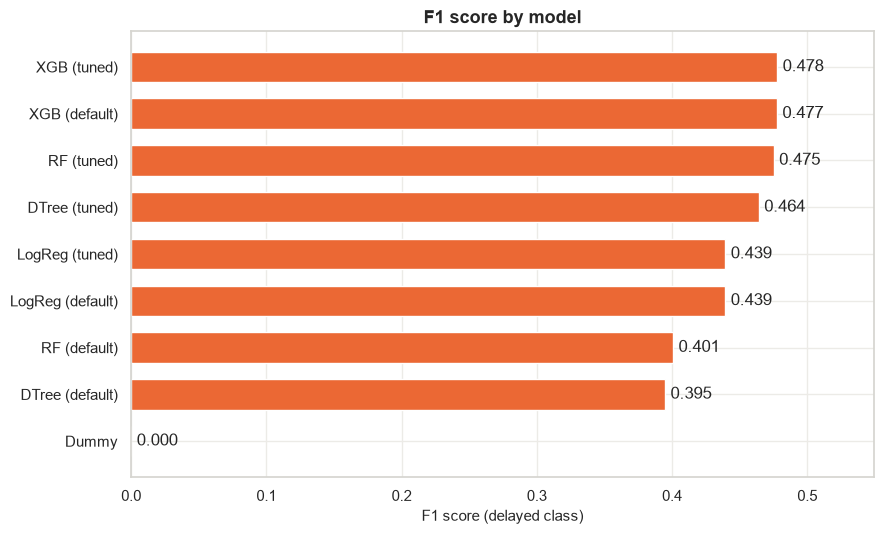

In [32]:
f1_sorted = summary.sort_values("F1 (delayed)")

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(f1_sorted["Model"], f1_sorted["F1 (delayed)"], color=COLOR_DELAYED, height=0.65)
ax.bar_label(bars, fmt="%.3f", padding=4)

ax.set_xlim(0, f1_sorted["F1 (delayed)"].max() * 1.15)
ax.set_xlabel("F1 score (delayed class)")
ax.set_title("F1 score by model")
plt.tight_layout()
plt.show()

#### ROC curves

A ROC curve shows how each model trades off catching delays (true positive rate) against false alarms (false positive rate) across **all** possible thresholds, not just 0.5. The closer a curve gets to the top-left corner, the better. The dashed diagonal is random guessing.

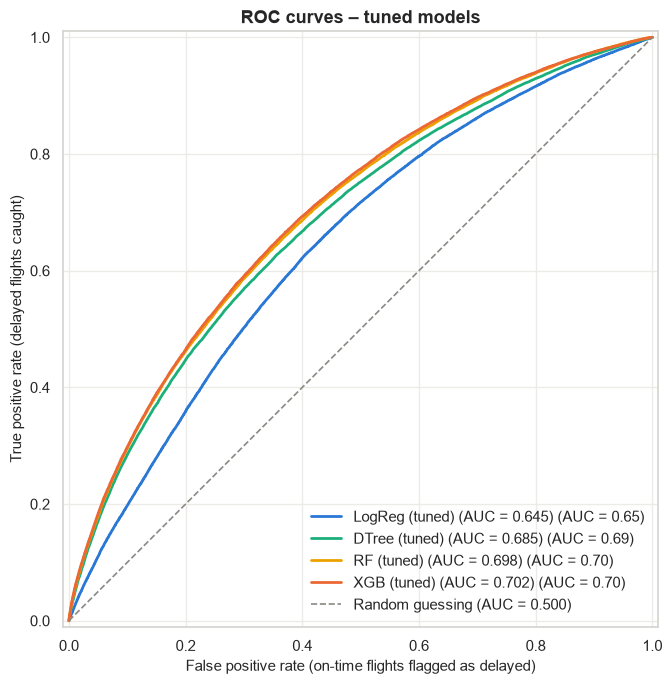

In [33]:
TUNED_MODELS = ["LogReg (tuned)", "DTree (tuned)", "RF (tuned)", "XGB (tuned)"]
MODEL_COLORS = {
    "LogReg (tuned)": COLOR_ONTIME,
    "DTree (tuned)": "#1baf7a",
    "RF (tuned)": "#eda100",
    "XGB (tuned)": COLOR_DELAYED,
}

fig, ax = plt.subplots(figsize=(7.5, 7))
for name in TUNED_MODELS:
    RocCurveDisplay.from_predictions(
        y_test, results[name]["y_proba"], ax=ax,
        name=f"{name} (AUC = {results[name]['auc']:.3f})",
        curve_kwargs={"color": MODEL_COLORS[name], "linewidth": 2},
    )
ax.plot([0, 1], [0, 1], color=COLOR_REF, linestyle="--", linewidth=1.2, label="Random guessing (AUC = 0.500)")

ax.set_xlabel("False positive rate (on-time flights flagged as delayed)")
ax.set_ylabel("True positive rate (delayed flights caught)")
ax.set_title("ROC curves – tuned models")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

#### Confusion matrices

The confusion matrices show the actual counts behind the metrics, at the default threshold of 0.5:

- **Top left:** on-time flights correctly predicted as on time.
- **Top right:** false alarms (on time, but predicted delayed).
- **Bottom left:** missed delays (delayed, but predicted on time).
- **Bottom right:** delays caught.

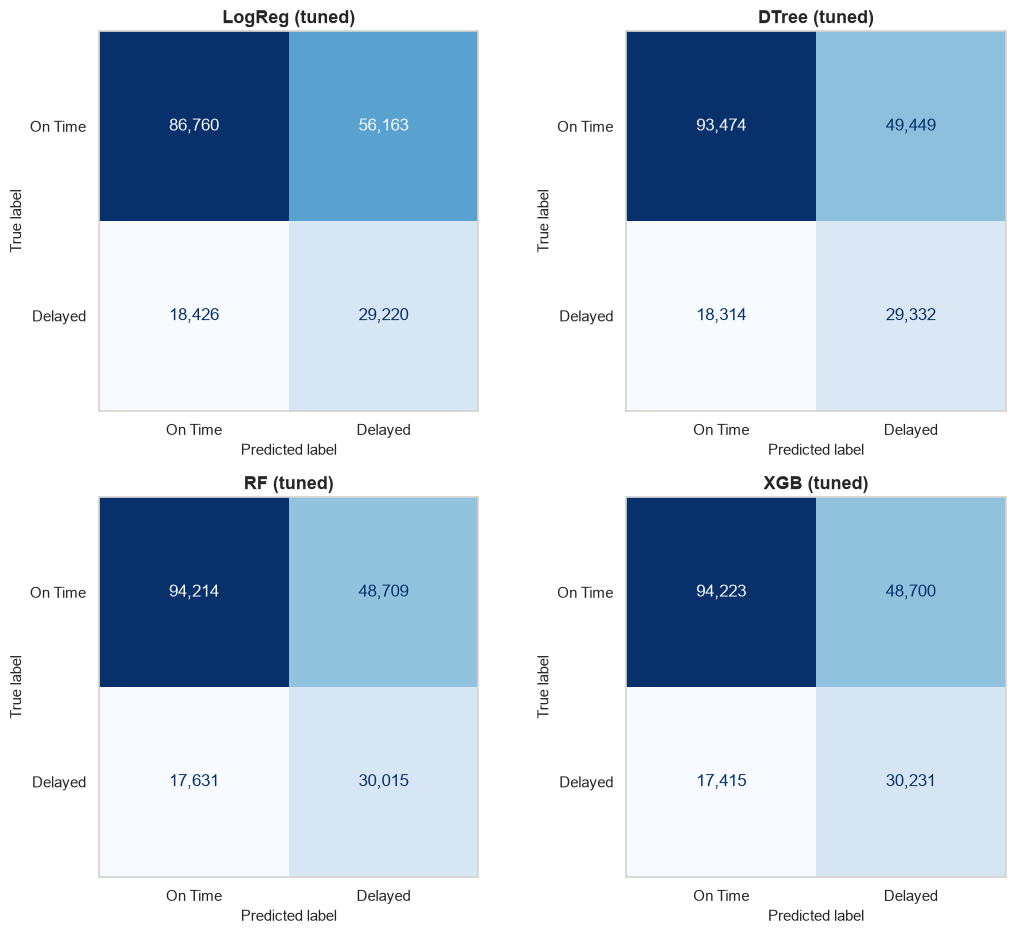

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))

for ax, name in zip(axes.flat, TUNED_MODELS):
    ConfusionMatrixDisplay.from_predictions(
        y_test, results[name]["y_pred"], display_labels=["On Time", "Delayed"],
        cmap="Blues", values_format=",", colorbar=False, ax=ax,
    )
    ax.set_title(name)
    ax.grid(False)

plt.tight_layout()
plt.show()

#### Conclusion

- **Each step up in model complexity helped, but the gains shrink.** F1 (delayed) and ROC-AUC for the tuned models:
  - Dummy: 0.000 / 0.500
  - Logistic Regression: 0.439 / 0.645
  - Decision Tree: 0.464 / 0.685
  - Random Forest: 0.475 / 0.698
  - XGBoost: **0.478 / 0.702**
- **XGBoost wins on both F1 and ROC-AUC.** It is also fast: the default model trains in 1 second and already beats the tuned Random Forest.
- **The problem is non-linear.** The biggest single jump is from logistic regression to a decision tree (+0.04 ROC-AUC). This matches the EDA: delays depend on ranges of `DepHour` and `Month` (the evening and summer peaks), not on straight-line effects.
- **Ensembles add a smaller extra gain.** Bagging (Random Forest) and boosting (XGBoost) add about another 0.015 ROC-AUC over the best single tree. Most of the benefit comes from capturing non-linearity at all; combining trees only refines it.
- **Tuning matters most for trees that overfit.** It made a large difference for the decision tree and Random Forest, whose defaults grow without limits, and almost none for logistic regression and XGBoost.

**Limitations:** A ROC-AUC of 0.70 is clearly better than guessing, but still modest. At the default threshold the best model catches about 63% of delays, but only about 38% of its delay warnings are correct, so most alerts are false alarms. The main reason is missing information: there is **no weather data**, and we don't know whether the incoming aircraft is already running late, even though late aircraft is the biggest cause of delays (41%, section 3.6). The schedule-only features can only tell the model which flights are *usually* risky, not which ones are at risk *today*.

**What could improve it:** Adding weather forecasts for the origin and destination, and features that follow each aircraft through its day via `Tail_Number` (such as the delay of its previous leg, if known 2 hours before departure), would most likely give the biggest improvement.